# Customer Lifetime Value & Segmentation Engine
**NextGen Institute · Machine Learning · Final Project**

An online gift retailer treats every customer the same. In this notebook we
(1) group customers by behaviour (unsupervised: RFM + K-Means) and
(2) predict how much each customer will spend in the **next 90 days** (supervised regression),
then combine both into a marketing tool.

Dataset: *Online Retail II* — UCI Machine Learning Repository, https://archive.ics.uci.edu/dataset/502

## 1 · Problem framing
| | |
|---|---|
| **Who has the problem?** | The marketing team of a UK online retailer (mostly wholesale gift buyers). |
| **Decision supported** | Who to reward, who to win back, where to spend the marketing budget. |
| **Target (supervised)** | `future_spend_90d` — total £ a customer spends in the 90 days after a cut-off date. |
| **Target (unsupervised)** | No label — customer segments from Recency / Frequency / Monetary (RFM). |
| **Metrics** | **MAE in £** (easy to explain: "on average we are off by £X") plus RMSE and R². MAE is the headline because spend is very skewed and RMSE is dominated by a few huge customers. |

**How we avoid leakage:** every feature is computed only from purchases **before** the cut-off date; the target only from purchases **after** it.

In [1]:
import warnings, json, os
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, RandomizedSearchCV, cross_val_score, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, RandomForestClassifier, GradientBoostingClassifier
from scipy.stats import spearmanr
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, mean_absolute_error, mean_squared_error, r2_score, roc_auc_score, precision_score, recall_score
import joblib
from sklearn.base import clone
RS = 42
sns.set_theme(style='whitegrid', context='notebook')
os.makedirs('figures', exist_ok=True); os.makedirs('artifacts', exist_ok=True)
def save(name): plt.tight_layout(); plt.savefig(f'figures/{name}.png', dpi=130); plt.show()

## 2 · Data understanding
Two Excel sheets (Dec 2009 – Dec 2011) were concatenated into one CSV. Each row is **one product line on one invoice**.

| Column | Meaning |
|---|---|
| `Invoice` | Invoice number (starts with **C** = cancellation / return) |
| `StockCode` | Product code |
| `Description` | Product name |
| `Quantity` | Units on the line (negative for returns) |
| `InvoiceDate` | Date & time of invoice |
| `Price` | Unit price in £ |
| `Customer ID` | Customer identifier (missing for guest checkouts) |
| `Country` | Customer country |

In [2]:
raw = pd.read_csv('data/online_retail_II.csv', parse_dates=['InvoiceDate'], dtype={'Invoice': str, 'StockCode': str})
print('shape:', raw.shape)
display(raw.head())
display(pd.DataFrame({'dtype': raw.dtypes.astype(str), 'missing': raw.isna().sum(), 'missing_%': (raw.isna().mean()*100).round(2)}))
print('date range:', raw.InvoiceDate.min(), '→', raw.InvoiceDate.max())
print('negative/zero quantity rows:', (raw.Quantity <= 0).sum(), '| zero/negative price rows:', (raw.Price <= 0).sum(),
      '| cancellation invoices (rows):', raw.Invoice.str.startswith('C').sum(), '| exact duplicate rows:', raw.duplicated().sum())

shape: (1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


,dtype,missing,missing_%
Invoice,str,0,0.00
StockCode,str,0,0.00
Description,str,4382,0.41
Quantity,int64,0,0.00
InvoiceDate,datetime64[us],0,0.00
Price,float64,0,0.00
Customer ID,float64,243007,22.77
Country,str,0,0.00


date range: 2009-12-01 07:45:00 → 2011-12-09 12:50:00


negative/zero quantity rows: 22950 | zero/negative price rows: 6207 | cancellation invoices (rows): 19494 | exact duplicate rows: 34335


**Class balance:** this is a regression + clustering problem, so there is no class balance to check. The target is, however, extremely skewed (see EDA) and many customers spend **£0** in the future window.

## 3 · Cleaning
* Cancellations are counted per customer (a *return rate* feature) and then removed from revenue.
* Rows without a `Customer ID` cannot be tied to a person → dropped (guest checkouts).
* Non-positive quantity/price, exact duplicates and non-product codes (postage, bank charges, manual adjustments…) are removed.

In [3]:
cancel_counts = (raw[raw.Invoice.str.startswith('C') & raw['Customer ID'].notna()]
                 .groupby('Customer ID').Invoice.nunique().rename('n_cancellations'))
df = raw.copy()
n0 = len(df)
steps = []
def step(name, mask):
    global df
    before = len(df); df = df[mask(df)]; steps.append((name, before - len(df)))
step('cancellation invoices (C…)', lambda d: ~d.Invoice.str.startswith('C'))
step('missing Customer ID', lambda d: d['Customer ID'].notna())
step('quantity <= 0 or price <= 0', lambda d: (d.Quantity > 0) & (d.Price > 0))
step('non-product stock codes (POST, D, M, BANK…)', lambda d: d.StockCode.str.match(r'^\d{5}'))
before = len(df); df = df.drop_duplicates(); steps.append(('exact duplicates', before - len(df)))
df['Customer ID'] = df['Customer ID'].astype(int)
df['Revenue'] = df.Quantity * df.Price
display(pd.DataFrame(steps, columns=['removed because', 'rows']).assign(pct_of_raw=lambda t: (t.rows / n0 * 100).round(2)))
print(f'clean rows: {len(df):,} ({len(df)/n0:.1%} of raw) | customers: {df["Customer ID"].nunique():,} | invoices: {df.Invoice.nunique():,}')

,removed because,rows,pct_of_raw
0,cancellation invoices (C…),19494,1.83
1,missing Customer ID,242257,22.70
2,quantity <= 0 or price <= 0,71,0.01
3,"non-product stock codes (POST, D, M, BANK…)",2917,0.27
4,exact duplicates,26055,2.44


clean rows: 776,577 (72.8% of raw) | customers: 5,852 | invoices: 36,594


## 4 · Building the target with a time cut-off (no leakage)
The data ends on 2011-12-09. We pick a **cut-off 90 days earlier**. Everything before the cut-off is "history" (features); the 90 days after it is the "future" (target).
Customers with no purchase before the cut-off are ignored (we cannot predict for someone we have never seen).

In [4]:
END = df.InvoiceDate.max().normalize() + pd.Timedelta(days=1)
CUTOFF = END - pd.Timedelta(days=90)
print('cut-off:', CUTOFF.date(), '| end:', END.date())
hist = df[df.InvoiceDate < CUTOFF]
fut = df[df.InvoiceDate >= CUTOFF]

g = hist.groupby('Customer ID')
inv = hist.groupby(['Customer ID', 'Invoice']).agg(date=('InvoiceDate', 'min'), val=('Revenue', 'sum')).reset_index()
gi = inv.groupby('Customer ID')
feat = pd.DataFrame({
    'recency_days': (CUTOFF - g.InvoiceDate.max()).dt.days,
    'frequency': gi.Invoice.nunique(),
    'monetary': g.Revenue.sum(),
    'avg_order_value': gi.val.mean(),
    'n_unique_products': g.StockCode.nunique(),
    'total_items': g.Quantity.sum(),
    'tenure_days': (CUTOFF - g.InvoiceDate.min()).dt.days,
})
feat['avg_days_between_orders'] = np.where(feat.frequency > 1, feat.tenure_days / (feat.frequency - 1).clip(lower=1), np.nan)
for d in (90, 180):
    h = hist[hist.InvoiceDate >= CUTOFF - pd.Timedelta(days=d)]
    feat[f'spend_last_{d}d'] = h.groupby('Customer ID').Revenue.sum().reindex(feat.index).fillna(0)
feat['orders_last_90d'] = (inv[inv.date >= CUTOFF - pd.Timedelta(days=90)].groupby('Customer ID').Invoice.nunique()
                           .reindex(feat.index).fillna(0))
feat['n_cancellations'] = cancel_counts.reindex(feat.index).fillna(0)   # cancellations are unaffected by the cut-off only approximately → see limitations
feat['is_uk'] = (g.Country.agg(lambda s: s.mode().iloc[0]) == 'United Kingdom').astype(int)
feat['future_spend_90d'] = fut.groupby('Customer ID').Revenue.sum().reindex(feat.index).fillna(0)
FEATURES = [c for c in feat.columns if c != 'future_spend_90d']
print('customers with history:', len(feat), '| share who buy again in the next 90 days:', f'{(feat.future_spend_90d > 0).mean():.1%}')
display(feat.describe().T.round(2))

cut-off: 2011-09-11 | end: 2011-12-10


customers with history: 5256 | share who buy again in the next 90 days: 43.6%


,count,mean,std,min,25%,50%,75%,max
recency_days,5256.0,206.89,174.37,1.00,50.00,164.00,325.00,648.00
frequency,5256.0,5.71,11.21,1.00,1.00,3.00,6.00,284.00
monetary,5256.0,2604.80,12095.39,1.55,316.61,776.56,2061.88,456780.49
avg_order_value,5256.0,369.91,638.14,1.55,173.88,275.15,407.24,25784.32
n_unique_products,5256.0,74.55,104.97,1.00,18.00,41.00,92.00,2178.00
total_items,5256.0,1627.59,8063.65,1.00,170.00,442.00,1207.00,297934.00
tenure_days,5256.0,431.67,180.69,1.00,311.00,474.00,587.00,648.00
avg_days_between_orders,3681.0,179.41,158.60,2.29,63.62,122.25,247.00,648.00
spend_last_90d,5256.0,345.75,1944.03,0.00,0.00,0.00,261.28,62151.70
spend_last_180d,5256.0,676.41,3329.85,0.00,0.00,109.45,545.72,120028.60


## 5 · Exploratory Data Analysis

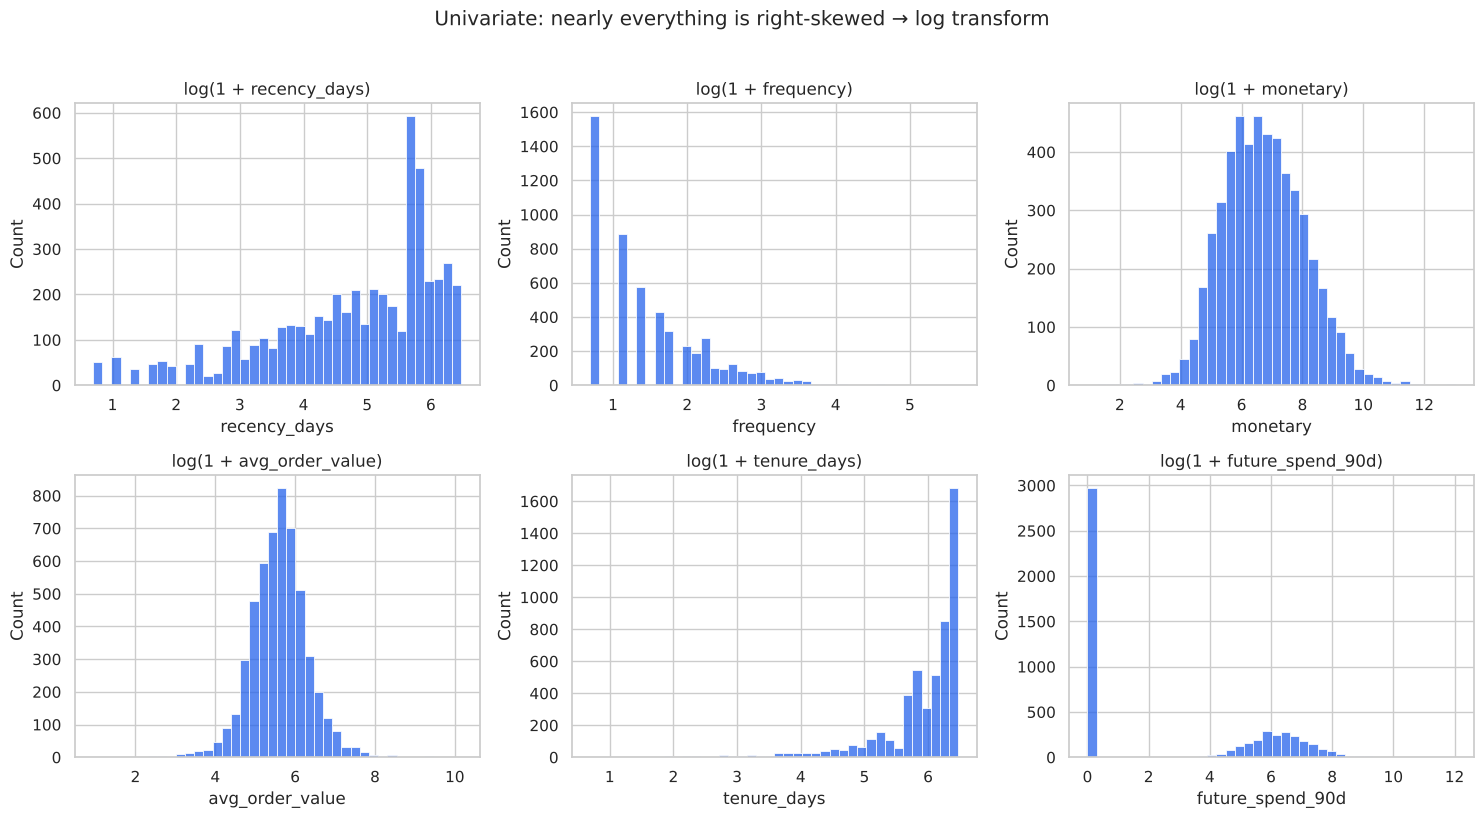

Top 20% of customers = 76.6% of historical revenue | 56.4% of customers spend £0 in the next 90 days


In [5]:
# --- Univariate -----------------------------------------------------------------
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for a, c in zip(ax.ravel(), ['recency_days', 'frequency', 'monetary', 'avg_order_value', 'tenure_days', 'future_spend_90d']):
    sns.histplot(np.log1p(feat[c]), bins=40, ax=a, color='#2563eb'); a.set_title(f'log(1 + {c})')
plt.suptitle('Univariate: nearly everything is right-skewed → log transform', y=1.02); save('eda_univariate')
top20 = feat.monetary.sort_values(ascending=False)
share_top20 = top20.head(int(len(top20) * .2)).sum() / top20.sum()
zero_share = (feat.future_spend_90d == 0).mean()
print(f'Top 20% of customers = {share_top20:.1%} of historical revenue | {zero_share:.1%} of customers spend £0 in the next 90 days')

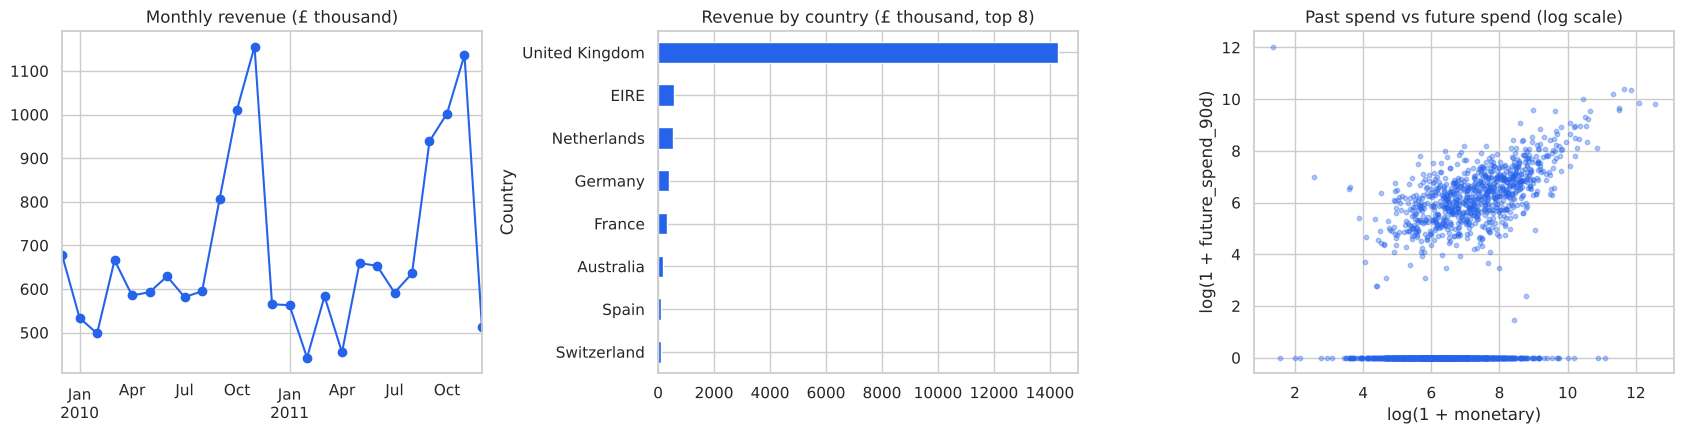

In [6]:
# --- Bivariate ------------------------------------------------------------------
monthly = df.set_index('InvoiceDate').Revenue.resample('MS').sum() / 1e3
cty = df.groupby('Country').Revenue.sum().sort_values(ascending=False).head(8) / 1e3
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
monthly.plot(ax=ax[0], marker='o', color='#2563eb'); ax[0].set_title('Monthly revenue (£ thousand)'); ax[0].set_xlabel('')
cty.iloc[::-1].plot.barh(ax=ax[1], color='#2563eb'); ax[1].set_title('Revenue by country (£ thousand, top 8)')
smp = feat.sample(2000, random_state=RS)
ax[2].scatter(np.log1p(smp.monetary), np.log1p(smp.future_spend_90d), alpha=.35, s=10, color='#2563eb')
ax[2].set_title('Past spend vs future spend (log scale)'); ax[2].set_xlabel('log(1 + monetary)'); ax[2].set_ylabel('log(1 + future_spend_90d)')
save('eda_bivariate')
peak = monthly.idxmax()
uk_share = cty['United Kingdom'] / (df.Revenue.sum() / 1e3)

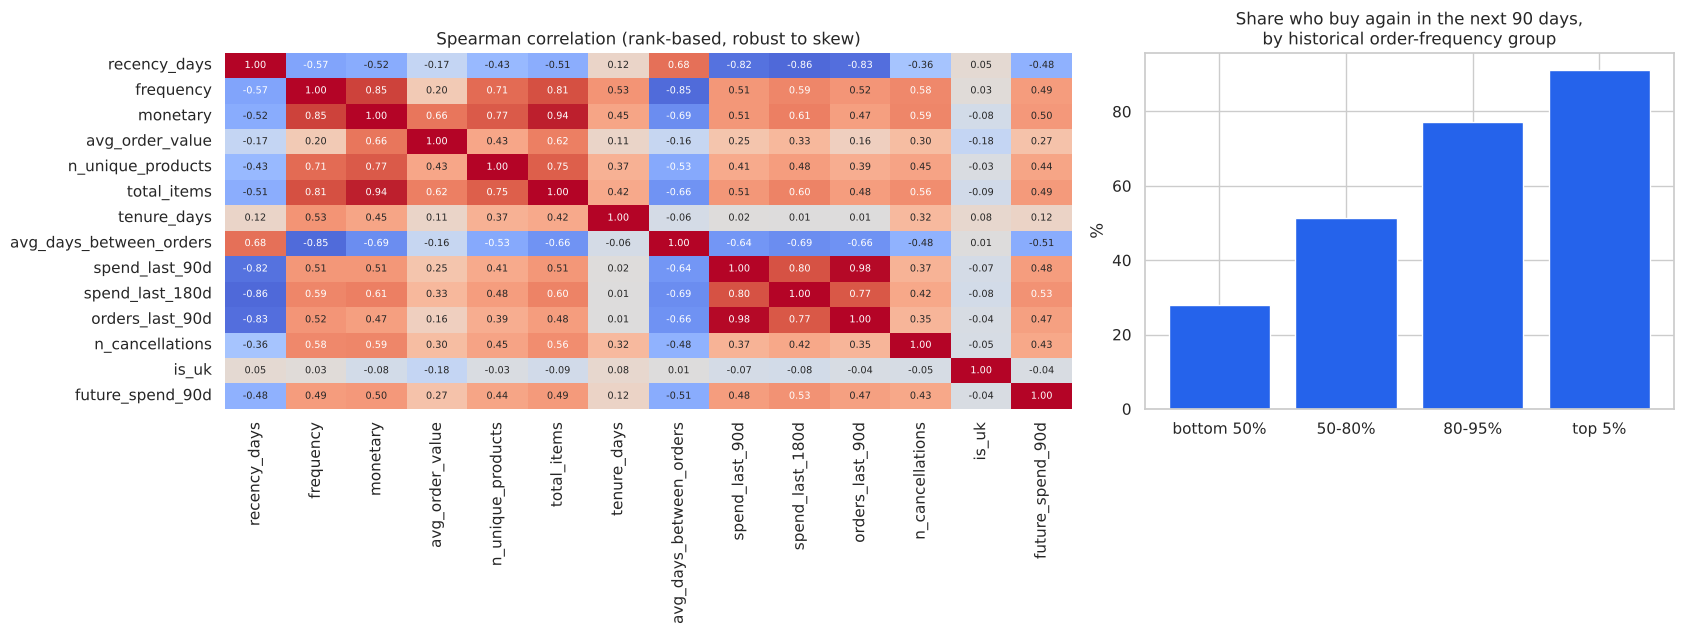

,customers,avg_future,repeat_rate
frequency,,,
bottom 50%,3041,217.97,0.28
50-80%,1170,361.48,0.51
80-95%,805,886.12,0.77
top 5%,240,4965.55,0.91


In [7]:
# --- Multivariate ---------------------------------------------------------------
corr = feat.assign(future_spend_90d=np.log1p(feat.future_spend_90d)).corr(method='spearman')
bins = pd.qcut(feat.frequency, [0, .5, .8, .95, 1], labels=['bottom 50%', '50-80%', '80-95%', 'top 5%'], duplicates='drop')
rep = feat.groupby(bins, observed=True).agg(customers=('frequency', 'size'), avg_future=('future_spend_90d', 'mean'), repeat_rate=('future_spend_90d', lambda s: (s > 0).mean()))
fig, ax = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={'width_ratios': [1.6, 1]})
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax[0], annot_kws={'size': 7}, cbar=False)
ax[0].set_title('Spearman correlation (rank-based, robust to skew)')
ax[1].bar(rep.index.astype(str), rep.repeat_rate * 100, color='#2563eb')
ax[1].set_title('Share who buy again in the next 90 days,\nby historical order-frequency group'); ax[1].set_ylabel('%')
save('eda_multivariate')
c_f = corr.loc['frequency', 'future_spend_90d']; c_r = corr.loc['recency_days', 'future_spend_90d']; c_s = corr.loc['spend_last_90d', 'future_spend_90d']
display(rep.round(2))

In [8]:
display(Markdown(f"""### Key insights / hypotheses (all numbers computed above)
1. **Revenue is concentrated:** the top 20% of customers generate **{share_top20:.0%}** of historical revenue → a small VIP group deserves special treatment.
2. **Most customers go quiet:** only **{1-zero_share:.0%}** of customers buy again in the next 90 days, so the target has a big spike at £0 (we model it on a log scale).
3. **Recency and frequency tell the story:** Spearman correlation with future spend is **{c_f:+.2f}** for frequency, **{c_r:+.2f}** for recency (days since last order) and **{c_s:+.2f}** for spend in the last 90 days.
4. **Seasonality:** revenue peaks in **{peak:%B %Y}** (Q4 gifting season) → our 90-day target window falls in peak season; a model trained on this window will over-estimate off-season spend (a limitation).
5. **UK dominates:** the UK is **{uk_share:.0%}** of revenue, so country adds little signal beyond a UK flag."""))

### Key insights / hypotheses (all numbers computed above)
1. **Revenue is concentrated:** the top 20% of customers generate **77%** of historical revenue → a small VIP group deserves special treatment.
2. **Most customers go quiet:** only **44%** of customers buy again in the next 90 days, so the target has a big spike at £0 (we model it on a log scale).
3. **Recency and frequency tell the story:** Spearman correlation with future spend is **+0.49** for frequency, **-0.48** for recency (days since last order) and **+0.48** for spend in the last 90 days.
4. **Seasonality:** revenue peaks in **November 2010** (Q4 gifting season) → our 90-day target window falls in peak season; a model trained on this window will over-estimate off-season spend (a limitation).
5. **UK dominates:** the UK is **84%** of revenue, so country adds little signal beyond a UK flag.

## 6 · Train / test split (customers) **before** fitting anything
All features already respect the cut-off, so a random customer split is safe. The scaler, K-Means and models below are fitted on the **training** customers only.

In [9]:
train_idx, test_idx = train_test_split(feat.index, test_size=.2, random_state=RS)
tr, te = feat.loc[train_idx], feat.loc[test_idx]
print(len(tr), 'train customers |', len(te), 'test customers')

4204 train customers | 1052 test customers


## 7 · Unsupervised part — customer segmentation
**RFM** = Recency, Frequency, Monetary. We log-transform (skew), standardise, and cluster.
First we choose *k* with the elbow (inertia) and silhouette score, then compare **K-Means** with **hierarchical (Ward)** clustering on a sample.

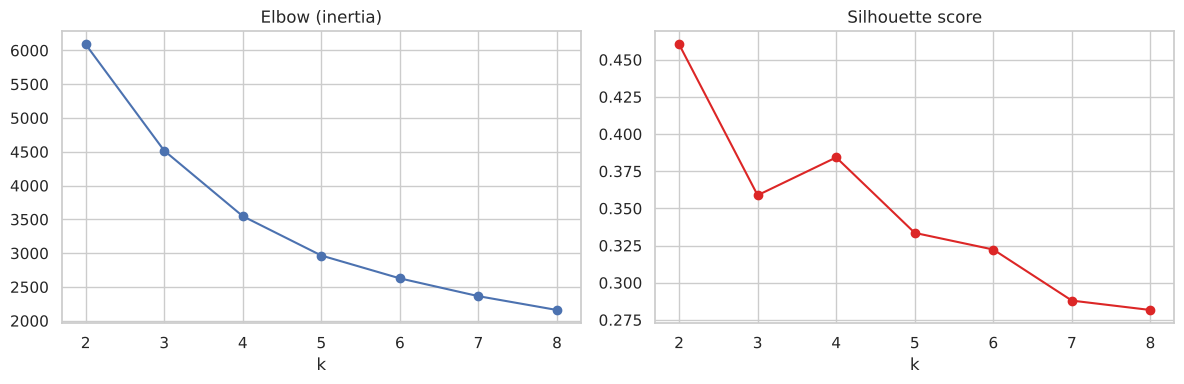

,k,inertia,silhouette
0,2,6090.0,0.460
1,3,4516.0,0.359
2,4,3547.0,0.384
3,5,2965.0,0.334
4,6,2627.0,0.322
5,7,2364.0,0.288
6,8,2159.0,0.282


In [10]:
RFM = ['recency_days', 'frequency', 'monetary']
rfm_pipe = Pipeline([('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')), ('scale', StandardScaler())])
Xr = rfm_pipe.fit_transform(tr[RFM])
ks = range(2, 9)
inertia, sil = [], []
for k in ks:
    km = KMeans(k, n_init=10, random_state=RS).fit(Xr)
    inertia.append(km.inertia_); sil.append(silhouette_score(Xr, km.labels_, sample_size=3000, random_state=RS))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, inertia, 'o-'); ax[0].set_title('Elbow (inertia)'); ax[0].set_xlabel('k')
ax[1].plot(ks, sil, 'o-', color='#dc2626'); ax[1].set_title('Silhouette score'); ax[1].set_xlabel('k')
save('segment_choose_k')
display(pd.DataFrame({'k': list(ks), 'inertia': np.round(inertia), 'silhouette': np.round(sil, 3)}))

In [11]:
K = 4
km = KMeans(K, n_init=20, random_state=RS).fit(Xr)
samp = np.random.RandomState(RS).choice(len(Xr), 3000, replace=False)
hc = AgglomerativeClustering(K, linkage='ward').fit(Xr[samp])
print(f'K-Means  (k={K}) silhouette on sample: {silhouette_score(Xr[samp], km.labels_[samp]):.3f}')
print(f'Ward hier. (k={K}) silhouette on sample: {silhouette_score(Xr[samp], hc.labels_):.3f}')
from sklearn.metrics import adjusted_rand_score
print(f'Agreement between the two (adjusted Rand index): {adjusted_rand_score(km.labels_[samp], hc.labels_):.2f}')

K-Means  (k=4) silhouette on sample: 0.384
Ward hier. (k=4) silhouette on sample: 0.325
Agreement between the two (adjusted Rand index): 0.59


We use **K = 4** — it keeps a reasonable silhouette while giving four groups a marketer can act on. K-Means is kept (simpler to deploy: new customers are assigned with `predict`, hierarchical clustering cannot score new points).

Now we name the clusters from their median RFM profile (printed below): the best RFM score is **Champions**, the worst is **Lost / Inactive**; of the two in the middle, the more recent one is **Promising** and the one with good past value that has gone quiet is **At Risk**.

In [12]:
tr = tr.assign(cluster=km.labels_)
prof = tr.groupby('cluster')[RFM].median()
score = (np.log1p(prof.frequency) - np.log1p(prof.frequency).mean()) / np.log1p(prof.frequency).std() \
      + (np.log1p(prof.monetary) - np.log1p(prof.monetary).mean()) / np.log1p(prof.monetary).std() \
      - (np.log1p(prof.recency_days) - np.log1p(prof.recency_days).mean()) / np.log1p(prof.recency_days).std()
order = score.sort_values().index.tolist()            # worst → best
best_c, lost_c = order[-1], order[0]
mid = [c for c in order[1:-1]]
recent_c = min(mid, key=lambda c: prof.recency_days[c])   # recent but still low-frequency
risk_c = [c for c in mid if c != recent_c][0]             # good past value, gone quiet
name_of = {best_c: 'Champions', recent_c: 'Promising', risk_c: 'At Risk', lost_c: 'Lost / Inactive'}
DISPLAY = ['Champions', 'Promising', 'At Risk', 'Lost / Inactive']
ACTIONS = {
    'Champions': 'Reward & retain: VIP early access, loyalty perks, no discounts needed.',
    'Promising': 'Nurture: second-purchase incentive and product recommendations while they are still engaged.',
    'At Risk': 'Win back: personalised reminder + time-limited offer — they have real past value but went quiet.',
    'Lost / Inactive': 'Low-cost reactivation only (email); do not spend heavy budget.',
}
display(prof.assign(segment=pd.Series(name_of)).set_index('segment').round(1).loc[DISPLAY])
def assign_segment(df_):
    return pd.Series(km.predict(rfm_pipe.transform(df_[RFM])), index=df_.index).map(name_of)
feat['segment'] = assign_segment(feat)
feat['split'] = np.where(feat.index.isin(train_idx), 'train', 'test')
seg_prof = feat.groupby('segment').agg(customers=('frequency', 'size'), median_recency_days=('recency_days', 'median'),
        median_orders=('frequency', 'median'), median_spend=('monetary', 'median'), historical_revenue=('monetary', 'sum'),
        repeat_rate_next_90d=('future_spend_90d', lambda s: (s > 0).mean()), avg_future_spend=('future_spend_90d', 'mean'),
        total_future_spend=('future_spend_90d', 'sum')).loc[DISPLAY]
seg_prof['share_of_customers_%'] = seg_prof.customers / seg_prof.customers.sum() * 100
seg_prof['share_of_future_revenue_%'] = seg_prof.total_future_spend / seg_prof.total_future_spend.sum() * 100
display(seg_prof.round(2))

,recency_days,frequency,monetary
segment,,,
Champions,20.0,13.0,4911.7
Promising,29.0,2.0,569.8
At Risk,166.0,5.0,1444.2
Lost / Inactive,327.0,1.0,295.4


,customers,median_recency_days,median_orders,median_spend,historical_revenue,repeat_rate_next_90d,avg_future_spend,total_future_spend,share_of_customers_%,share_of_future_revenue_%
segment,,,,,,,,,,
Champions,908,20.0,13.0,4911.74,9321407.75,0.84,2064.08,1874185.73,17.28,62.66
Promising,677,29.0,2.0,572.82,478863.56,0.55,379.87,257173.33,12.88,8.60
At Risk,1582,166.0,5.0,1440.42,3178846.08,0.46,328.13,519102.87,30.10,17.36
Lost / Inactive,2089,327.0,1.0,292.21,711707.55,0.20,162.93,340365.29,39.75,11.38


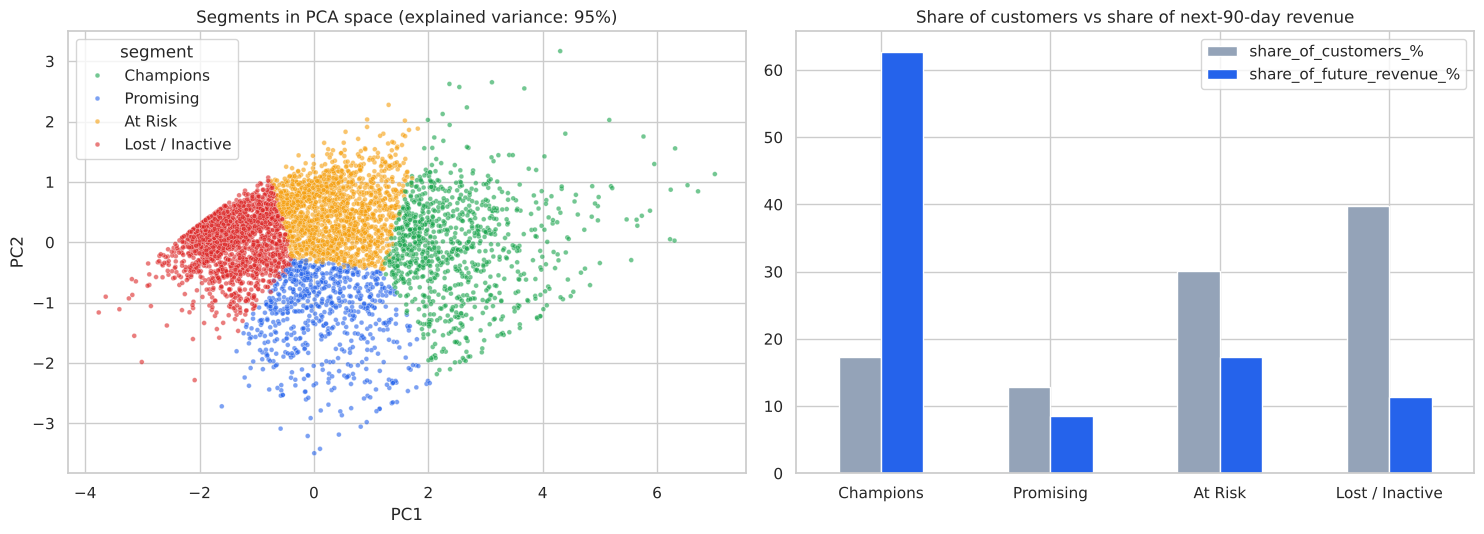

**Champions** are **17%** of customers but **63%** of next-90-day revenue.

In [13]:
pca = PCA(2, random_state=RS).fit(Xr)
P = pca.transform(rfm_pipe.transform(feat[RFM]))
pal = dict(zip(DISPLAY, ['#16a34a', '#2563eb', '#f59e0b', '#dc2626']))
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=feat.segment, palette=pal, s=12, alpha=.6, ax=ax[0], hue_order=DISPLAY)
ax[0].set_title(f'Segments in PCA space (explained variance: {pca.explained_variance_ratio_.sum():.0%})'); ax[0].set_xlabel('PC1'); ax[0].set_ylabel('PC2')
(seg_prof[['share_of_customers_%', 'share_of_future_revenue_%']].plot.bar(ax=ax[1], color=['#94a3b8', '#2563eb']))
ax[1].set_title('Share of customers vs share of next-90-day revenue'); ax[1].set_xlabel(''); ax[1].tick_params(axis='x', rotation=0)
save('segments')
champ = seg_prof.loc['Champions']
display(Markdown(f"**Champions** are **{champ['share_of_customers_%']:.0f}%** of customers but **{champ['share_of_future_revenue_%']:.0f}%** of next-90-day revenue."))

## 8 · Supervised part — predict next-90-day spend
**Why a two-part model?** 56% of customers spend exactly £0 in the future window and the rest are heavily right-skewed. A single regressor on this target either ignores the zeros or (when trained on log-spend) **systematically under-predicts total revenue** — we tested this (see 9). The standard CLV solution is:

`expected spend  =  P(customer buys again)  ×  E[spend | buys]`

* **Part A – classifier:** will the customer buy in the next 90 days? (`future_spend_90d > 0`)
* **Part B – regressor:** how much will they spend *if* they buy? (trained on buyers only, target `log1p(spend)`, with a bias correction when converting back to £)

### 8.1 Preprocessing inside a scikit-learn `Pipeline`
Median imputation (for `avg_days_between_orders` of one-time buyers), `log1p` for skewed features, standardisation.

In [14]:
SKEWED = ['recency_days', 'frequency', 'monetary', 'avg_order_value', 'n_unique_products', 'total_items', 'tenure_days',
          'avg_days_between_orders', 'spend_last_90d', 'spend_last_180d', 'orders_last_90d', 'n_cancellations']
PLAIN = ['is_uk']
def make_pre():
    skew = Pipeline([('imp', SimpleImputer(strategy='median')), ('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')), ('sc', StandardScaler())])
    return ColumnTransformer([('skew', skew, SKEWED), ('plain', 'passthrough', PLAIN)])
def pipe(model): return Pipeline([('pre', make_pre()), ('model', model)])
buy_tr = (tr.future_spend_90d > 0).astype(int); buy_te = (te.future_spend_90d > 0).astype(int)
buyers = tr[tr.future_spend_90d > 0]
print(f'Part A: {len(tr)} training customers, {buy_tr.mean():.1%} buy again | Part B: {len(buyers)} training buyers')
skf = StratifiedKFold(5, shuffle=True, random_state=RS); kf = KFold(5, shuffle=True, random_state=RS)

Part A: 4204 training customers, 43.4% buy again | Part B: 1823 training buyers


### 8.2 Baselines + three algorithms per part (5-fold CV on training data)
* Part A baseline: always predict the training buy-rate (ROC-AUC = 0.5). Part B baseline: predict the mean log-spend of buyers.

In [15]:
clf_models = {'Logistic Regression': LogisticRegression(max_iter=2000), 'Random Forest': RandomForestClassifier(300, min_samples_leaf=5, n_jobs=-1, random_state=RS),
              'Gradient Boosting': GradientBoostingClassifier(random_state=RS)}
reg_models = {'Baseline (mean)': DummyRegressor(), 'Ridge': Ridge(), 'Random Forest': RandomForestRegressor(300, min_samples_leaf=5, n_jobs=-1, random_state=RS),
              'Gradient Boosting': GradientBoostingRegressor(random_state=RS)}
ra = [{'model': n, 'CV ROC-AUC': cross_val_score(pipe(m), tr[FEATURES], buy_tr, cv=skf, scoring='roc_auc', n_jobs=-1).mean()} for n, m in clf_models.items()]
rb = [{'model': n, 'CV MAE (log £)': -cross_val_score(pipe(m), buyers[FEATURES], np.log1p(buyers.future_spend_90d), cv=kf, scoring='neg_mean_absolute_error', n_jobs=-1).mean()} for n, m in reg_models.items()]
display(Markdown('**Part A – will they buy?**')); display(pd.DataFrame(ra).set_index('model').round(3))
display(Markdown('**Part B – how much if they buy?**')); display(pd.DataFrame(rb).set_index('model').round(3))

**Part A – will they buy?**

,CV ROC-AUC
model,
Logistic Regression,0.795
Random Forest,0.792
Gradient Boosting,0.795


**Part B – how much if they buy?**

,CV MAE (log £)
model,
Baseline (mean),0.824
Ridge,0.576
Random Forest,0.589
Gradient Boosting,0.587


### 8.3 Hyper-parameter tuning (RandomizedSearchCV, training data only)
The winner of each part is chosen by **cross-validation score only** — the test set is not used to choose anything.

In [16]:
gA = {'Logistic Regression': (LogisticRegression(max_iter=2000), {'model__C': np.logspace(-3, 2, 20)}),
      'Random Forest': (RandomForestClassifier(n_jobs=-1, random_state=RS), {'model__n_estimators': [200, 400], 'model__max_depth': [4, 6, 8, None], 'model__min_samples_leaf': [3, 5, 10, 20], 'model__max_features': ['sqrt', 0.5]}),
      'Gradient Boosting': (GradientBoostingClassifier(random_state=RS), {'model__n_estimators': [100, 200, 300], 'model__learning_rate': [0.02, 0.05, 0.1], 'model__max_depth': [2, 3, 4], 'model__subsample': [0.7, 0.9, 1.0], 'model__min_samples_leaf': [5, 10, 20]})}
gB = {'Ridge': (Ridge(), {'model__alpha': np.logspace(-2, 3, 30)}),
      'Random Forest': (RandomForestRegressor(n_jobs=-1, random_state=RS), {'model__n_estimators': [200, 400], 'model__max_depth': [3, 5, 8, None], 'model__min_samples_leaf': [3, 5, 10, 20], 'model__max_features': ['sqrt', 0.5, 1.0]}),
      'Gradient Boosting': (GradientBoostingRegressor(random_state=RS), {'model__n_estimators': [100, 200, 300], 'model__learning_rate': [0.02, 0.05, 0.1], 'model__max_depth': [2, 3, 4], 'model__subsample': [0.7, 0.9, 1.0], 'model__min_samples_leaf': [5, 10, 20]})}
def tune(grid, X, y, cv, scoring):
    out = {}
    for n, (m, g_) in grid.items():
        rs = RandomizedSearchCV(pipe(m), g_, n_iter=12, cv=cv, scoring=scoring, random_state=RS, n_jobs=-1).fit(X, y)
        out[n] = (rs.best_estimator_, rs.best_score_, {k.replace('model__', ''): v for k, v in rs.best_params_.items()})
    return out
tA = tune(gA, tr[FEATURES], buy_tr, skf, 'roc_auc')
tB = tune(gB, buyers[FEATURES], np.log1p(buyers.future_spend_90d), kf, 'neg_mean_absolute_error')
display(Markdown('**Part A tuned**')); display(pd.DataFrame([{'model': n, 'tuned CV ROC-AUC': v[1], 'best params': v[2]} for n, v in tA.items()]).set_index('model'))
display(Markdown('**Part B tuned**')); display(pd.DataFrame([{'model': n, 'tuned CV MAE (log £)': -v[1], 'best params': v[2]} for n, v in tB.items()]).set_index('model'))
nameA = max(tA, key=lambda n: tA[n][1]); nameB = max(tB, key=lambda n: tB[n][1])
clf, reg = tA[nameA][0], tB[nameB][0]
print(f'Selected by CV → Part A: {nameA} | Part B: {nameB}')

**Part A tuned**

,tuned CV ROC-AUC,best params
model,,
Logistic Regression,0.795914,{'C': 0.02069138081114789}
Random Forest,0.799151,"{'n_estimators': 200, 'min_samples_leaf': 3, '..."
Gradient Boosting,0.799464,"{'subsample': 0.7, 'n_estimators': 300, 'min_s..."


**Part B tuned**

,tuned CV MAE (log £),best params
model,,
Ridge,0.575239,{'alpha': 0.01}
Random Forest,0.580445,"{'n_estimators': 400, 'min_samples_leaf': 10, ..."
Gradient Boosting,0.576795,"{'subsample': 0.7, 'n_estimators': 300, 'min_s..."


Selected by CV → Part A: Gradient Boosting | Part B: Ridge


### 8.4 Putting the two parts together
`E[spend | buys]` is `exp(prediction)` on the log scale, which on average is *lower* than the true mean (Jensen's inequality). Two safeguards, both using **training data only**:
1. predictions on the log scale are clipped to the range seen in training buyers (a linear model can extrapolate wildly for extreme customers);
2. a **calibration factor** = (total real spend of training buyers) ÷ (total spend implied by their cross-validated predictions). We use this ratio of sums instead of the textbook "smearing" average of `exp(residual)` because the latter is dominated by a handful of outliers.

In [17]:
ylog = np.log1p(buyers.future_spend_90d)
LOG_RANGE = (float(ylog.min()), float(ylog.max()))
oof = np.clip(cross_val_predict(clone(reg), buyers[FEATURES], ylog, cv=kf), *LOG_RANGE)
SMEAR = float(np.expm1(ylog).sum() / np.expm1(oof).sum())
print(f'calibration factor = {SMEAR:.3f}')
from clv_utils import predict_clv
models = {'clf': clf, 'reg': reg, 'smear': SMEAR, 'log_range': LOG_RANGE}

calibration factor = 1.620


## 9 · Final evaluation on the untouched test set
Metrics in **£**: MAE (headline), RMSE, R². We also show ROC-AUC of Part A, the ranking quality (Spearman), and how well **total revenue** is predicted (sum predicted ÷ sum actual). Comparators:
* *Baseline (mean)* – predict the same average £ for everybody.
* *Baseline (median)* – predict £0 for everybody (most customers spend nothing).
* *Single GB on log-spend* – the simple one-model approach we rejected.

In [18]:
y = te.future_spend_90d
def metrics_row(name, p):
    p = np.clip(p, 0, None)
    top = te.index[np.argsort(-p, kind='stable')][:len(te) // 5]
    return {'model': name, 'MAE £': mean_absolute_error(y, p), 'RMSE £': mean_squared_error(y, p) ** .5, 'R² (£)': r2_score(y, p),
            'Spearman': spearmanr(y, p)[0] if np.std(p) > 0 else np.nan, 'top-20% revenue capture': y.loc[top].sum() / y.sum(), 'Σ pred / Σ actual': p.sum() / y.sum()}
single = pipe(GradientBoostingRegressor(random_state=RS)).fit(tr[FEATURES], np.log1p(tr.future_spend_90d))
p_buy = clf.predict_proba(te[FEATURES])[:, 1]; p_two = predict_clv(models, te[FEATURES])['expected_spend']
res = pd.DataFrame([metrics_row('Baseline (mean £)', np.full(len(te), tr.future_spend_90d.mean())), metrics_row('Baseline (median = £0)', np.zeros(len(te))),
                    metrics_row('Single GB on log-spend', np.expm1(single.predict(te[FEATURES]))),
                    metrics_row(f'Two-part ({nameA} × {nameB})', p_two.values)]).set_index('model')
display(res.round(3))
auc = roc_auc_score(buy_te, p_buy)
print(f'Part A test ROC-AUC: {auc:.3f} (CV was {tA[nameA][1]:.3f}) | precision/recall @0.5: {precision_score(buy_te, p_buy > .5):.2f} / {recall_score(buy_te, p_buy > .5):.2f}')
two, one = res.iloc[-1], res.loc['Single GB on log-spend']
display(Markdown(f"""**Reading the table honestly:** every model beats both baselines. The one-model log-spend regressor has a slightly lower MAE (£{one['MAE £']:.0f} vs £{two['MAE £']:.0f}) — MAE rewards predicting small numbers when most customers spend £0 — **but it only predicts {one['Σ pred / Σ actual']:.0%} of the real total revenue**, so it cannot be used to size "revenue at stake". The two-part model gives a calibrated total ({two['Σ pred / Σ actual']:.0%} of actual on this test set) **and** a purchase probability, so it is the one we deploy."""))

,MAE £,RMSE £,R² (£),Spearman,top-20% revenue capture,Σ pred / Σ actual
model,,,,,,
Baseline (mean £),741.680,1992.684,-0.001,NaN,0.219,1.095
Baseline (median = £0),528.908,2061.072,-0.070,NaN,0.219,0.000
Single GB on log-spend,385.081,1371.195,0.526,0.605,0.746,0.443
Two-part (Gradient Boosting × Ridge),443.749,1388.124,0.514,0.578,0.754,1.200


Part A test ROC-AUC: 0.818 (CV was 0.799) | precision/recall @0.5: 0.74 / 0.64


**Reading the table honestly:** every model beats both baselines. The one-model log-spend regressor has a slightly lower MAE (£385 vs £444) — MAE rewards predicting small numbers when most customers spend £0 — **but it only predicts 44% of the real total revenue**, so it cannot be used to size "revenue at stake". The two-part model gives a calibrated total (120% of actual on this test set) **and** a purchase probability, so it is the one we deploy.

### Error analysis

,customers,actual_mean,predicted_mean,MAE
segment,,,,
Champions,182,2092.1,2384.6,1349.2
Promising,143,291.4,392.5,290.4
At Risk,320,311.0,425.4,384.5
Lost / Inactive,407,84.7,101.7,139.3


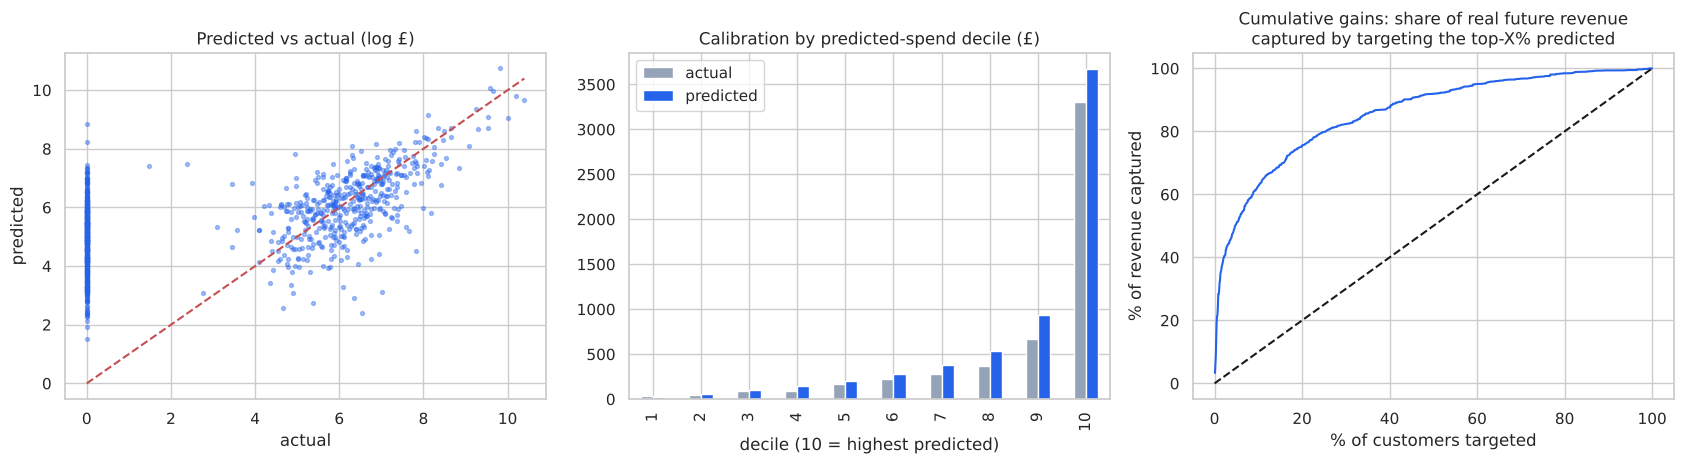

* Targeting the **top 20%** of customers ranked by the model captures **75%** of next-90-day revenue (random targeting = 20%).
* Total predicted revenue is **120%** of actual (the single-model alternative gets 44%).
* Weak spot: the **very biggest spenders** (top 1% of test customers: actual mean £17,886 vs predicted £16,675) are under-predicted — typical for heavy-tailed money data, and the largest source of RMSE.

In [19]:
te_res = te.assign(pred=p_two.values, p_buy=p_buy, segment=feat.loc[te.index, 'segment'])
te_res['abs_err'] = (te_res.pred - te_res.future_spend_90d).abs()
seg_err = te_res.groupby('segment').agg(customers=('pred', 'size'), actual_mean=('future_spend_90d', 'mean'), predicted_mean=('pred', 'mean'), MAE=('abs_err', 'mean')).loc[DISPLAY]
display(seg_err.round(1))
te_res['decile'] = pd.qcut(te_res.pred.rank(method='first'), 10, labels=False) + 1
dec = te_res.groupby('decile').agg(actual=('future_spend_90d', 'mean'), predicted=('pred', 'mean'))
cum = te_res.sort_values('pred', ascending=False, kind='stable').future_spend_90d.cumsum() / te_res.future_spend_90d.sum()
top20_capture = float(cum.iloc[int(len(cum) * .2) - 1])
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
ax[0].scatter(np.log1p(te_res.future_spend_90d), np.log1p(te_res.pred), s=8, alpha=.4, color='#2563eb'); lim = [0, np.log1p(te_res.future_spend_90d).max()]
ax[0].plot(lim, lim, 'r--'); ax[0].set_title('Predicted vs actual (log £)'); ax[0].set_xlabel('actual'); ax[0].set_ylabel('predicted')
dec.plot.bar(ax=ax[1], color=['#94a3b8', '#2563eb']); ax[1].set_title('Calibration by predicted-spend decile (£)'); ax[1].set_xlabel('decile (10 = highest predicted)')
ax[2].plot(np.arange(1, len(cum) + 1) / len(cum) * 100, cum.values * 100, color='#2563eb'); ax[2].plot([0, 100], [0, 100], 'k--')
ax[2].set_title('Cumulative gains: share of real future revenue\ncaptured by targeting the top-X% predicted'); ax[2].set_xlabel('% of customers targeted'); ax[2].set_ylabel('% of revenue captured')
save('evaluation')
big = te_res.sort_values('future_spend_90d', ascending=False).head(max(5, len(te_res) // 100))
display(Markdown(f"""* Targeting the **top 20%** of customers ranked by the model captures **{top20_capture:.0%}** of next-90-day revenue (random targeting = 20%).
* Total predicted revenue is **{res.iloc[-1]['Σ pred / Σ actual']:.0%}** of actual (the single-model alternative gets {res.iloc[2]['Σ pred / Σ actual']:.0%}).
* Weak spot: the **very biggest spenders** (top 1% of test customers: actual mean £{big.future_spend_90d.mean():,.0f} vs predicted £{big.pred.mean():,.0f}) are under-predicted — typical for heavy-tailed money data, and the largest source of RMSE."""))

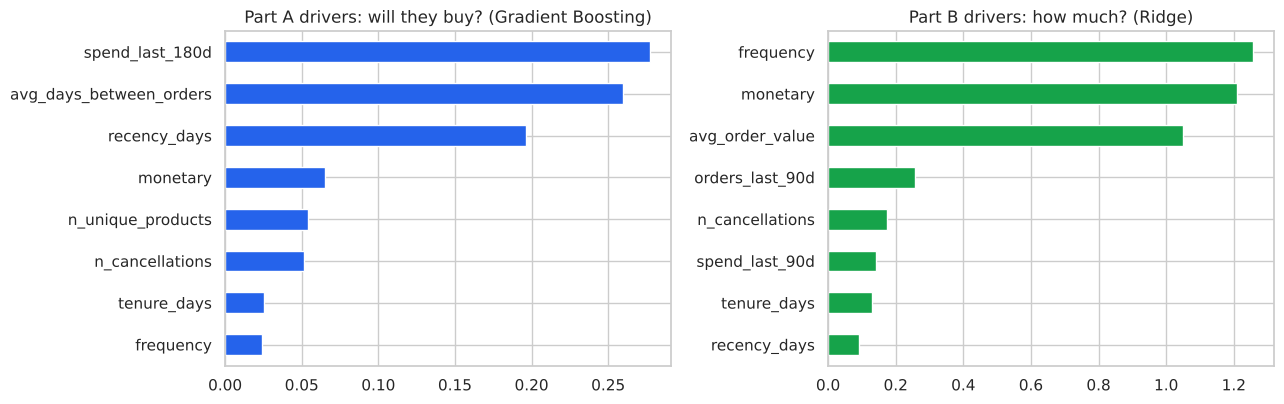

In [20]:
def importances(est):
    pre_, m_ = est.named_steps['pre'], est.named_steps['model']
    fn = [n.split('__')[-1] for n in pre_.get_feature_names_out()]
    v = m_.feature_importances_ if hasattr(m_, 'feature_importances_') else np.abs(np.ravel(m_.coef_))
    return pd.Series(v, fn).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
importances(clf).tail(8).plot.barh(ax=ax[0], color='#2563eb'); ax[0].set_title(f'Part A drivers: will they buy? ({nameA})')
importances(reg).tail(8).plot.barh(ax=ax[1], color='#16a34a'); ax[1].set_title(f'Part B drivers: how much? ({nameB})')
save('feature_importance')

## 10 · Business insight & recommendation
Expected next-90-day revenue per segment from the model, next to what customers actually spent, plus the recommended action.

In [21]:
feat['pred_spend_90d'] = predict_clv(models, feat[FEATURES])['expected_spend']
biz = feat.groupby('segment').agg(customers=('pred_spend_90d', 'size'), predicted_90d_revenue=('pred_spend_90d', 'sum'), actual_90d_revenue=('future_spend_90d', 'sum')).loc[DISPLAY]
biz['recommended action'] = [ACTIONS[s] for s in biz.index]
display(biz.round(0))
risk = feat[feat.segment == 'At Risk']; risk_rev = risk.monetary.sum()
display(Markdown(f"""### What the company should do
1. **Protect Champions** – {champ['share_of_customers_%']:.0f}% of customers but {champ['share_of_future_revenue_%']:.0f}% of future revenue. Invest in service and perks, not blanket discounts.
2. **Win back the At-Risk group** – **{len(risk):,} customers** who spent **£{risk_rev:,.0f}** historically but have been silent for a median of {risk.recency_days.median():.0f} days. A reminder + time-limited offer is cheap compared with what is at stake.
3. **Nurture Promising customers** – recent but low-frequency: a second-purchase incentive is the highest-leverage moment.
4. **Stop heavy spending on Lost customers** – only {seg_prof.loc['Lost / Inactive','repeat_rate_next_90d']:.0%} buy again; use low-cost email only.
5. **Prioritise outreach with the model score** – the top 20% by predicted spend capture {top20_capture:.0%} of next-90-day revenue.

### Limitations
* One cut-off only (Sept 2011) and the target window is the **Q4 peak season** → absolute £ values are seasonal; use scores mainly to **rank** customers.
* One UK wholesaler of gifts — behaviour may not transfer to other retailers.
* Only purchase history is used (no web behaviour, marketing contacts or margin) so "revenue" is not profit.
* `n_cancellations` is counted over the whole dataset period (a minor look-ahead for a few customers; its importance is low).
* Models are fitted on the training customers only (not refit on the test customers), so the reported test scores describe exactly the deployed model."""))

,customers,predicted_90d_revenue,actual_90d_revenue,recommended action
segment,,,,
Champions,908,1920776.0,1874186.0,"Reward & retain: VIP early access, loyalty per..."
Promising,677,265369.0,257173.0,Nurture: second-purchase incentive and product...
At Risk,1582,660616.0,519103.0,Win back: personalised reminder + time-limited...
Lost / Inactive,2089,224452.0,340365.0,Low-cost reactivation only (email); do not spe...


### What the company should do
1. **Protect Champions** – 17% of customers but 63% of future revenue. Invest in service and perks, not blanket discounts.
2. **Win back the At-Risk group** – **1,582 customers** who spent **£3,178,846** historically but have been silent for a median of 166 days. A reminder + time-limited offer is cheap compared with what is at stake.
3. **Nurture Promising customers** – recent but low-frequency: a second-purchase incentive is the highest-leverage moment.
4. **Stop heavy spending on Lost customers** – only 20% buy again; use low-cost email only.
5. **Prioritise outreach with the model score** – the top 20% by predicted spend capture 75% of next-90-day revenue.

### Limitations
* One cut-off only (Sept 2011) and the target window is the **Q4 peak season** → absolute £ values are seasonal; use scores mainly to **rank** customers.
* One UK wholesaler of gifts — behaviour may not transfer to other retailers.
* Only purchase history is used (no web behaviour, marketing contacts or margin) so "revenue" is not profit.
* `n_cancellations` is counted over the whole dataset period (a minor look-ahead for a few customers; its importance is low).
* Models are fitted on the training customers only (not refit on the test customers), so the reported test scores describe exactly the deployed model.

## 11 · Save artifacts for the web app

In [22]:
joblib.dump(models, 'artifacts/clv_model.joblib')
joblib.dump({'rfm_pipe': rfm_pipe, 'kmeans': km, 'name_of': name_of, 'names': DISPLAY, 'actions': ACTIONS, 'features': FEATURES,
             'rfm': RFM, 'cutoff': str(CUTOFF.date()), 'pca': pca}, 'artifacts/segmenter.joblib')
feat['p_buy'] = clf.predict_proba(feat[FEATURES])[:, 1]
app_cols = ['segment', 'p_buy', 'pred_spend_90d'] + FEATURES
feat[app_cols].round(3).reset_index().rename(columns={'Customer ID': 'customer_id'}).to_csv('artifacts/customers.csv', index=False)
seg_prof.round(2).reset_index().to_csv('artifacts/segment_profile.csv', index=False)
biz.round(0).reset_index().to_csv('artifacts/segment_revenue.csv', index=False)
metrics = {'part_a': nameA, 'part_b': nameB, 'smear': round(SMEAR, 3), 'cutoff': str(CUTOFF.date()), 'n_customers': int(len(feat)), 'n_train': len(tr), 'n_test': len(te),
           'test': res.round(3).to_dict('index'), 'test_roc_auc_buy': round(float(auc), 3), 'top20_revenue_capture': round(top20_capture, 3), 'k': K,
           'silhouette_kmeans': round(float(silhouette_score(Xr[samp], km.labels_[samp])), 3), 'rows_raw': int(len(raw)), 'rows_clean': int(len(df)),
           'buy_again_rate': round(float((feat.future_spend_90d > 0).mean()), 3), 'top20_hist_share': round(float(share_top20), 3)}
json.dump(metrics, open('artifacts/metrics.json', 'w'), indent=2, default=float)
print(json.dumps(metrics, indent=2, default=float))

{
  "part_a": "Gradient Boosting",
  "part_b": "Ridge",
  "smear": 1.62,
  "cutoff": "2011-09-11",
  "n_customers": 5256,
  "n_train": 4204,
  "n_test": 1052,
  "test": {
    "Baseline (mean \u00a3)": {
      "MAE \u00a3": 741.68,
      "RMSE \u00a3": 1992.684,
      "R\u00b2 (\u00a3)": -0.001,
      "Spearman": NaN,
      "top-20% revenue capture": 0.219,
      "\u03a3 pred / \u03a3 actual": 1.095
    },
    "Baseline (median = \u00a30)": {
      "MAE \u00a3": 528.908,
      "RMSE \u00a3": 2061.072,
      "R\u00b2 (\u00a3)": -0.07,
      "Spearman": NaN,
      "top-20% revenue capture": 0.219,
      "\u03a3 pred / \u03a3 actual": 0.0
    },
    "Single GB on log-spend": {
      "MAE \u00a3": 385.081,
      "RMSE \u00a3": 1371.195,
      "R\u00b2 (\u00a3)": 0.526,
      "Spearman": 0.605,
      "top-20% revenue capture": 0.746,
      "\u03a3 pred / \u03a3 actual": 0.443
    },
    "Two-part (Gradient Boosting \u00d7 Ridge)": {
      "MAE \u00a3": 443.749,
      "RMSE \u00a3": 1388.124,